In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_excel(r"C:\Users\Prade\OneDrive\Desktop\EDA_PROJECT\online_retail.xlsx")
df.head()



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [3]:
df.to_csv("online_retail.csv",index=False)
df=pd.read_csv("online_retail.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [4]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
df=df.dropna(subset=["Description","CustomerID"])
df.isna().sum()


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [6]:
df[df.duplicated()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [7]:
df=df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [8]:
cancelled=df[df["InvoiceNo"].astype(str).str.startswith("C")]
cancelled["InvoiceNo"].nunique()
cancelled.shape

(8872, 8)

In [9]:
df[df["Quantity"]<=0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [10]:
df[df["Quantity"]>0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [11]:
df[df["UnitPrice"]<=0]
(df["UnitPrice"]<=0).sum()


np.int64(40)

In [59]:
df["Revenue"]=df["Quantity"]*df["UnitPrice"]
df["Revenue"].sum()

np.float64(8278519.424)

In [13]:
sales_df=df[df["Quantity"]>0].copy()
sales_df
return_df=df[df["Quantity"]<=0].copy()
return_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
...,...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom,-9.13
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom,-224.69
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom,-54.75
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom,-1.25


In [14]:

print("Inavalid Quantity:",(df["Quantity"]<=0).sum())
print("Inavalid UnitPrice:",(df["UnitPrice"]<=0).sum())

Inavalid Quantity: 8872
Inavalid UnitPrice: 40


In [56]:
df[["Quantity","UnitPrice","Revenue"]]

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
...,...,...,...
541904,12,0.85,10.20
541905,6,2.10,12.60
541906,4,4.15,16.60
541907,4,4.15,16.60


In [16]:
df["InvoiceDate"].dtype

dtype('O')

In [17]:
df["InvoiceDate"]=pd.to_datetime(df["InvoiceDate"])
df["InvoiceDate"].dtype

dtype('<M8[ns]')

In [18]:
df["year"]=df["InvoiceDate"].dt.year
df["Month"]=df["InvoiceDate"].dt.month
df["Day"]=df["InvoiceDate"].dt.day
df["DayName"]=df["InvoiceDate"].dt.day_name()
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,year,Month,Day,DayName
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,1,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,1,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1,Wednesday
...,...,...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,2011,12,9,Friday
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011,12,9,Friday
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,12,9,Friday
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,12,9,Friday


In [19]:
df[["Quantity","UnitPrice","Revenue"]].describe()

,Quantity,UnitPrice,Revenue
count,401604.000000,401604.000000,401604.000000
mean,12.183273,3.474064,20.613638
std,250.283037,69.764035,430.352218
min,-80995.000000,0.000000,-168469.600000
25%,2.000000,1.250000,4.250000
50%,5.000000,1.950000,11.700000
75%,12.000000,3.750000,19.800000
max,80995.000000,38970.000000,168469.600000


In [20]:
df[["UnitPrice","Quantity"]].nunique()

UnitPrice    620
Quantity     436
dtype: int64

<Axes: >

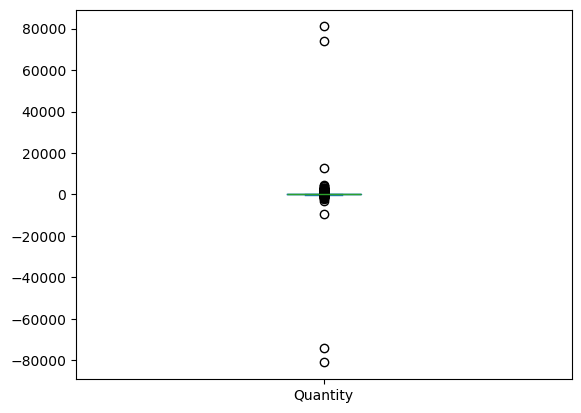

In [21]:
df["Quantity"].plot(kind="box")

In [22]:
df["Quantity"].nlargest(10)


540421    80995
61619     74215
502122    12540
421632     4800
206121     4300
97432      3906
270885     3186
52711      3114
160546     3114
433788     3000
Name: Quantity, dtype: int64

In [23]:
df["UnitPrice"].nlargest(10)

222681    38970.00
173277     8142.75
173382     8142.75
173391     6930.00
268027     4287.63
422351     4161.06
422375     4161.06
422376     4161.06
406404     3949.32
406406     3949.32
Name: UnitPrice, dtype: float64

In [24]:
Monthly_Revenue=df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()
Monthly_Revenue

InvoiceDate
2010-12     552372.860
2011-01     473731.900
2011-02     435534.070
2011-03     578576.210
2011-04     425222.671
2011-05     647011.670
2011-06     606862.520
2011-07     573112.321
2011-08     615078.090
2011-09     929356.232
2011-10     973306.380
2011-11    1126815.070
2011-12     341539.430
Freq: M, Name: Revenue, dtype: float64

<Axes: xlabel='InvoiceDate'>

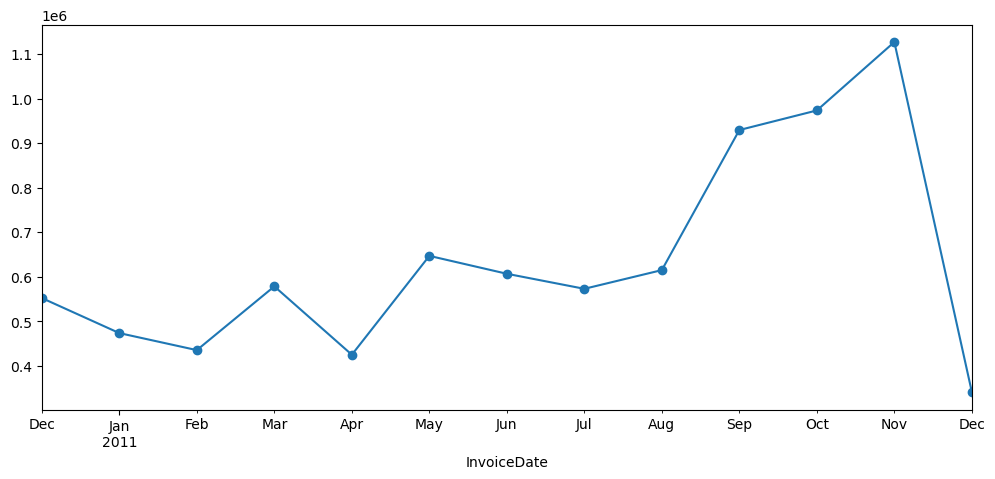

In [25]:
Monthly_Revenue.plot(kind="line",figsize=(12,5),marker="o")

In [26]:
Monthly_Revenue.sort_values(ascending=False)

InvoiceDate
2011-11    1126815.070
2011-10     973306.380
2011-09     929356.232
2011-05     647011.670
2011-08     615078.090
2011-06     606862.520
2011-03     578576.210
2011-07     573112.321
2010-12     552372.860
2011-01     473731.900
2011-02     435534.070
2011-04     425222.671
2011-12     341539.430
Freq: M, Name: Revenue, dtype: float64

In [27]:
Monthly_Revenue.max()

1126815.07

In [28]:
Monthly_Revenue.min()

341539.43

<Axes: xlabel='Country'>

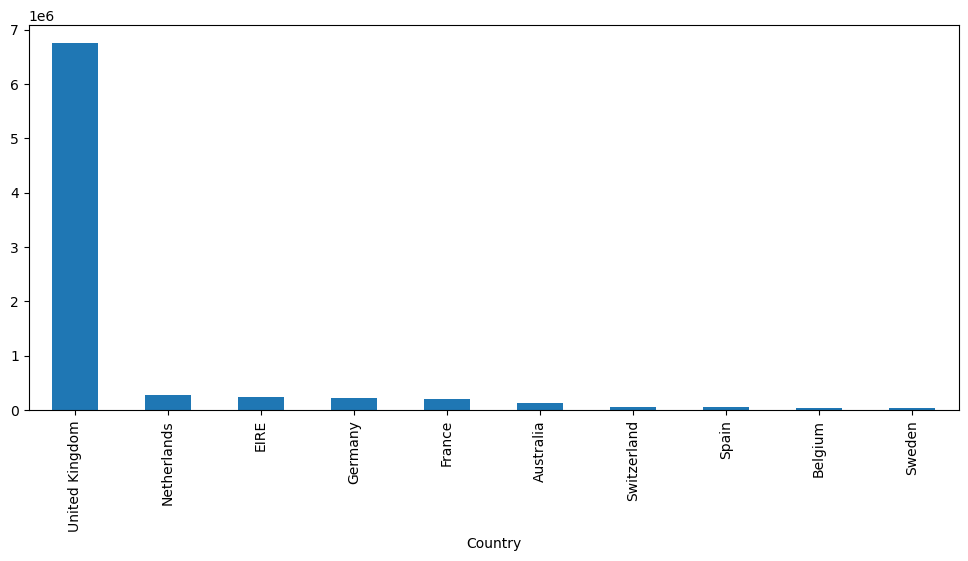

In [29]:
Country_revenue=df.groupby("Country")["Revenue"].sum()
Country_revenue.sort_values(ascending=False).head(10)
Country_revenue.sort_values(ascending=False).head(10).plot(kind="bar",figsize=(12,5))

<Axes: xlabel='Country'>

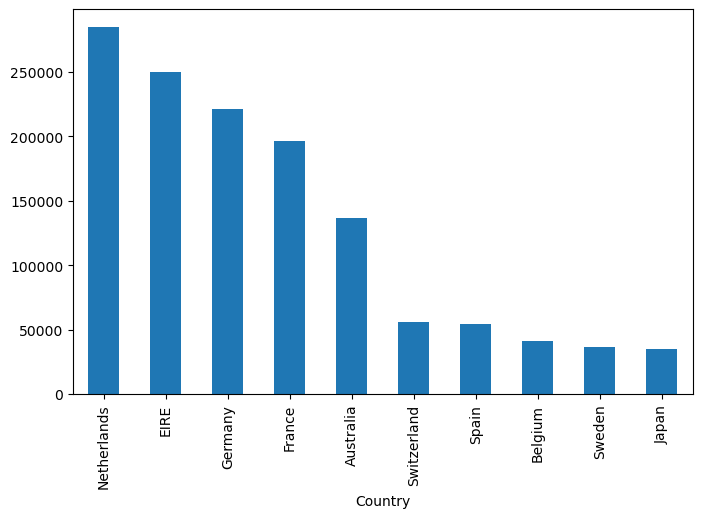

In [30]:
Country_revenue_without_uk=Country_revenue.drop('United Kingdom')
Country_revenue_without_uk.sort_values(ascending=False).head(10).plot(kind="bar",figsize=(8,5))


Text(0.5, 1.0, 'Top 10 Products by Revenue')

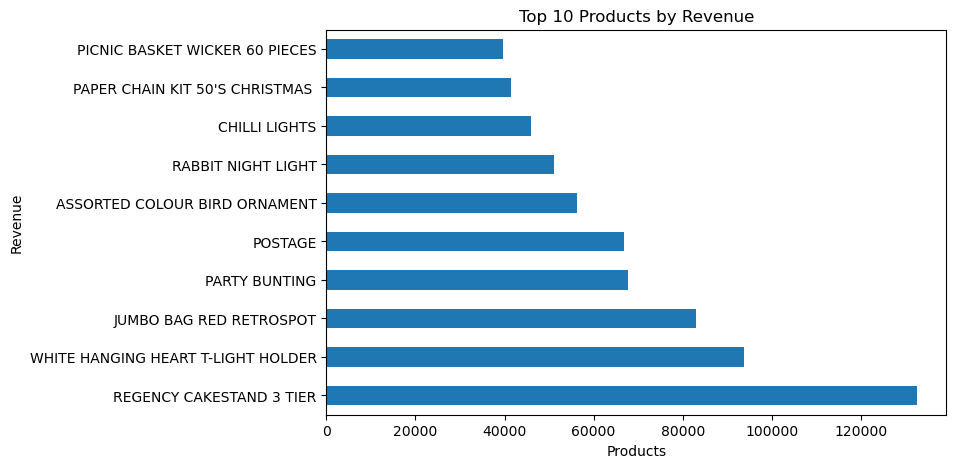

In [31]:
Product_revenue=df.groupby("Description")["Revenue"].sum()
top_products=Product_revenue.sort_values(ascending=False).head(10)
top_products.plot(kind="barh",figsize=(8,5))
plt.xlabel("Products")
plt.ylabel("Revenue")
plt.title("Top 10 Products by Revenue")

Text(0.5, 1.0, 'Top 10 Products by Quantity')

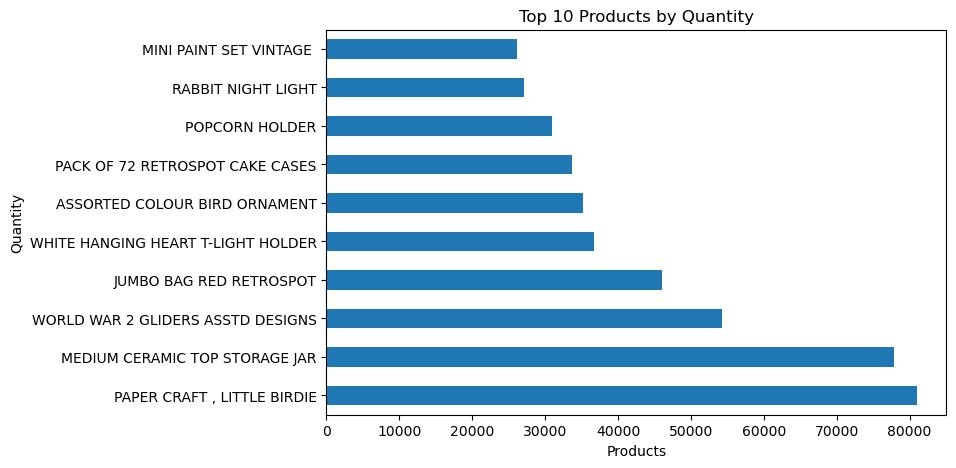

In [32]:
Product_Quantity=df[df["Quantity"]>0].groupby("Description")["Quantity"].sum()
Top_Quantity_Products=Product_Quantity.sort_values(ascending=False).head(10)
Top_Quantity_Products.plot(kind="barh",figsize=(8,5))
plt.xlabel("Products")
plt.ylabel("Quantity")
plt.title("Top 10 Products by Quantity")

Text(0.5, 1.0, 'Top 10 Customers by Revenue')

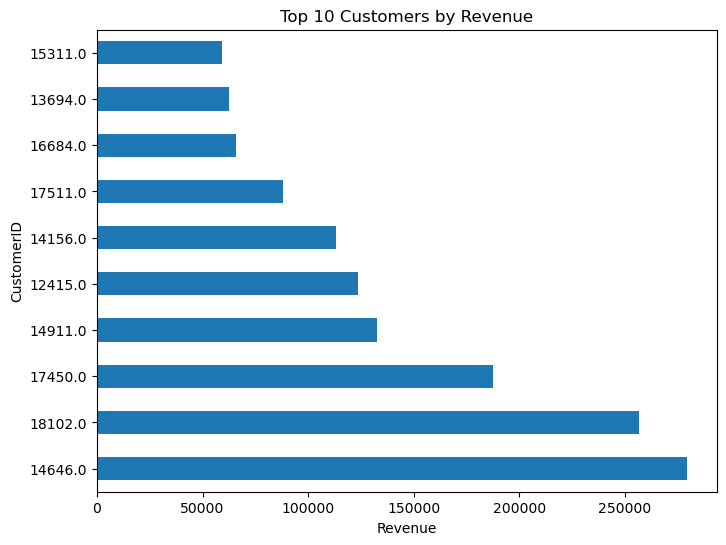

In [33]:
Customer_revenue=df.groupby("CustomerID")["Revenue"].sum()
Top_Customers=Customer_revenue.sort_values(ascending=False).head(10)
Top_Customers.plot(kind="barh",figsize=(8,6))
plt.xlabel("Revenue")
plt.ylabel("CustomerID")
plt.title("Top 10 Customers by Revenue")

Text(0.5, 1.0, 'Top 10 Customers by Purchase Frequency')

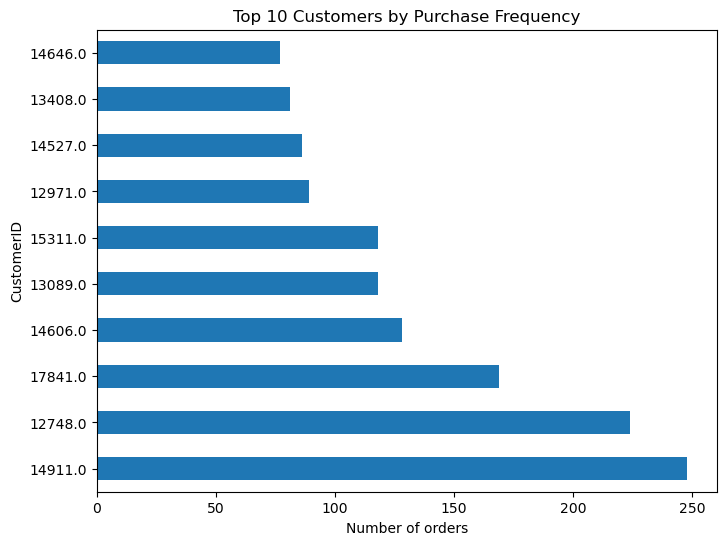

In [34]:
Customer_Frequency=df.groupby("CustomerID")["InvoiceNo"].nunique()
Top_Customer_Frequency=Customer_Frequency.sort_values(ascending=False).head(10)
Top_Customer_Frequency.plot(kind="barh",figsize=(8,6))
plt.xlabel("Number of orders")
plt.ylabel("CustomerID")
plt.title("Top 10 Customers by Purchase Frequency")

In [35]:
return_df=df[df["InvoiceNo"].astype(str).str.startswith("C")].copy()
return_df["InvoiceNo"].nunique()
return_df["Quantity"].abs().sum()
return_df["ReturnValue"]=return_df["Quantity"].abs()*return_df["UnitPrice"]
return_df["ReturnValue"].sum()

np.float64(608689.47)

In [36]:
return_products= ( return_df.groupby("Description")["Quantity"].sum().abs().sort_values(ascending=False).head(10))
return_products

Description
PAPER CRAFT , LITTLE BIRDIE            80995
MEDIUM CERAMIC TOP STORAGE JAR         74494
ROTATING SILVER ANGELS T-LIGHT HLDR     9367
Manual                                  3995
FAIRY CAKE FLANNEL ASSORTED COLOUR      3150
WHITE HANGING HEART T-LIGHT HOLDER      2578
GIN + TONIC DIET METAL SIGN             2030
HERB MARKER BASIL                       1527
FELTCRAFT DOLL MOLLY                    1447
TEA TIME PARTY BUNTING                  1424
Name: Quantity, dtype: int64

Text(0.5, 1.0, 'Top 10 Most Returned Product')

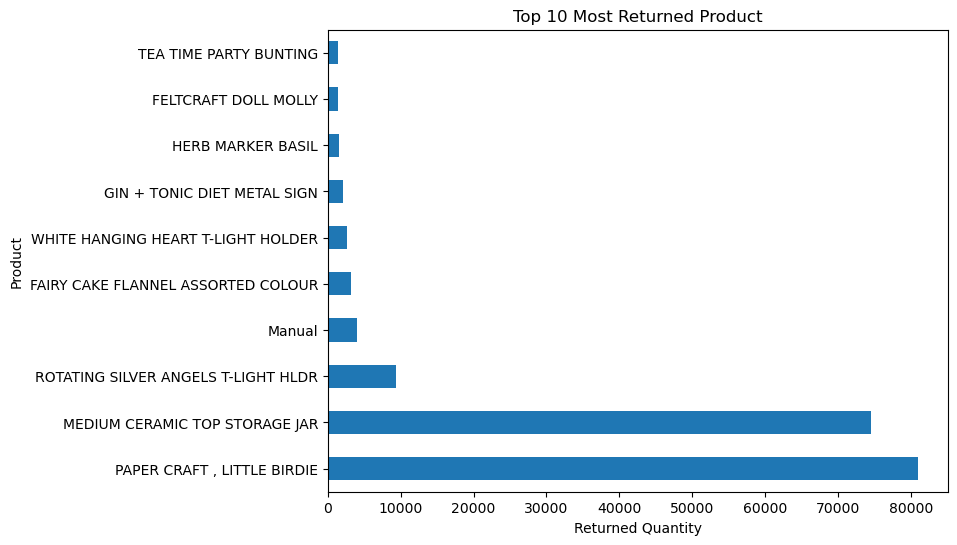

In [37]:
return_products.plot(kind="barh",figsize=(8,6))
plt.ylabel("Product")
plt.xlabel("Returned Quantity")
plt.title("Top 10 Most Returned Product")

In [38]:
Sold_Quantity=df[df["Quantity"]>0]["Quantity"].sum()
print("Total Sold Quantity:",Sold_Quantity)
Returned_Quantity=return_df["Quantity"].abs().sum()
print("Total Returned Quantity:",Returned_Quantity)


Total Sold Quantity: 5165886
Total Returned Quantity: 273035


In [39]:
Return_rate=(Returned_Quantity/Sold_Quantity)*100
print("Return rate:",Return_rate,"%")

Return rate: 5.285346985976848 %


In [40]:
Monthly_Sales=(df[df["Quantity"]>0].groupby(df["InvoiceDate"].dt.to_period("M"))["Quantity"].sum())
Monthly_Returns=return_df.groupby(df["InvoiceDate"].dt.to_period("M"))["Quantity"].sum().abs()
Monthly_Sales_Returns=pd.DataFrame({"sold":Monthly_Sales,
                                    "Returned":Monthly_Returns}).fillna(0)
Monthly_Sales_Returns


,sold,Returned
InvoiceDate,,
2010-12,311063,15886
2011-01,348522,79767
2011-02,265043,2800
2011-03,347623,4528
2011-04,291369,13639
2011-05,372948,5833
2011-06,363014,6775
2011-07,367372,6013
2011-08,398190,12325


Text(0.5, 1.0, 'Monthly Sales VS Returns')

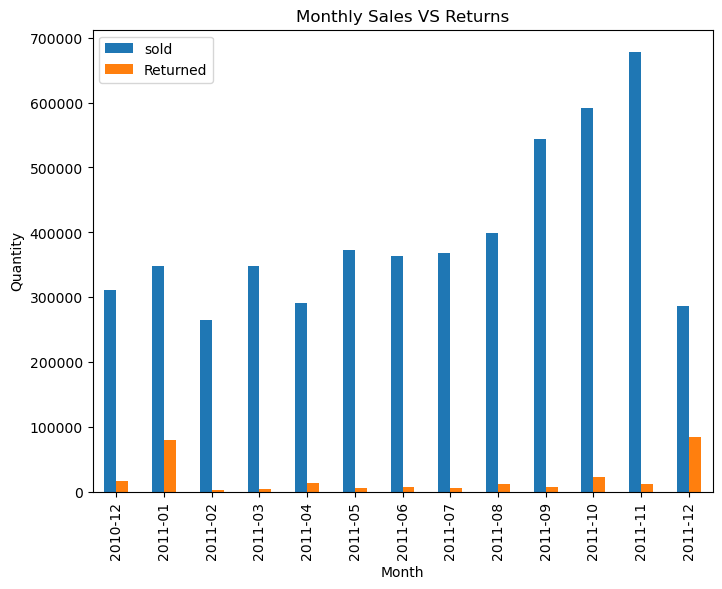

In [41]:
Monthly_Sales_Returns.plot(kind="bar",figsize=(8,6))
plt.xlabel("Month")
plt.ylabel("Quantity")
plt.title("Monthly Sales VS Returns")

In [42]:
Order_revenue=df[df["Quantity"]>0].groupby("InvoiceNo")["Revenue"].sum()
AOV=Order_revenue.mean()
print("Average_Order_Value:",AOV)

Average_Order_Value: 479.45667317652135


In [43]:
Order_revenue.sort_values(ascending=False).head(10)

InvoiceNo
581483    168469.60
541431     77183.60
556444     38970.00
567423     31698.16
556917     22775.93
572209     22206.00
567381     22104.80
563614     21880.44
550461     21535.90
572035     20277.92
Name: Revenue, dtype: float64

In [44]:
Reference_Date=df["InvoiceDate"].max()+pd.Timedelta(days=1)
Reference_Date

Timestamp('2011-12-10 12:50:00')

In [45]:
df["InvoiceDate"]=pd.to_datetime(df["InvoiceDate"])
df["InvoiceDate"].dtype
sales_df=df[df["Quantity"]>0].copy()


In [46]:
RFM=sales_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",lambda x:(Reference_Date-x.max()).days),
    Frequency=("InvoiceNo","nunique"),
    Monetary=("Revenue","sum")
)
RFM.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [54]:
# Create RFM scores
RFM["R_Score"]=pd.qcut(RFM["Recency"],5,labels=[1,2,3,4,5])
RFM["F_Score"]=pd.qcut(RFM["Frequency"].rank(method='first'),5,labels=[5,4,3,2,1])
RFM["M_Score"]=pd.qcut(RFM["Monetary"],5,labels=[1,2,3,4,5])
RFM


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Scores,Segment
CustomerID,,,,,,,,
12346.0,326,1,77183.60,5,5,5,15,High Value
12347.0,2,7,4310.00,1,1,5,7,Potential
12348.0,75,4,1797.24,4,2,4,10,Loyal
12349.0,19,1,1757.55,2,5,4,11,Loyal
12350.0,310,1,334.40,5,5,2,12,Loyal
...,...,...,...,...,...,...,...,...
18280.0,278,1,180.60,5,4,1,10,Loyal
18281.0,181,1,80.82,5,4,1,10,Loyal
18282.0,8,2,178.05,1,3,1,5,At Risk


In [48]:
#create overall RFM scores
RFM["RFM_Scores"]=(RFM["R_Score"].astype(int)+
                 RFM["F_Score"].astype(int)+
                 RFM["M_Score"].astype(int)
                )
RFM["RFM_Scores"]

CustomerID
12346.0    15
12347.0     7
12348.0    10
12349.0    11
12350.0    12
           ..
18280.0    10
18281.0    10
18282.0     5
18283.0     6
18287.0     9
Name: RFM_Scores, Length: 4339, dtype: int64

In [49]:
RFM.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Scores
CustomerID,,,,,,,
12346.0,326,1,77183.60,5,5,5,15
12347.0,2,7,4310.00,1,1,5,7
12348.0,75,4,1797.24,4,2,4,10
12349.0,19,1,1757.55,2,5,4,11
12350.0,310,1,334.40,5,5,2,12


In [50]:
RFM.sort_values("RFM_Scores",ascending=False).head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Scores
CustomerID,,,,,,,
12346.0,326,1,77183.60,5,5,5,15
14439.0,320,1,2661.24,5,5,5,15
12501.0,337,1,2169.39,5,5,5,15
13135.0,197,1,3096.00,5,5,5,15
12752.0,81,1,4366.78,4,5,5,14


In [51]:
def segment_customer(x):
    if x["RFM_Scores"]>=13:
        return "High Value"
    elif x["RFM_Scores"]>=10:
        return "Loyal"
    elif x["RFM_Scores"]>=7:
        return "Potential"
    elif x["RFM_Scores"]>=4:
        return "At Risk"
    else:
        return "Lost"

RFM["Segment"]=RFM.apply(segment_customer,axis=1)      
    

In [52]:
RFM[["Segment","RFM_Scores"]].value_counts

<bound method DataFrame.value_counts of                Segment  RFM_Scores
CustomerID                        
12346.0     High Value          15
12347.0      Potential           7
12348.0          Loyal          10
12349.0          Loyal          11
12350.0          Loyal          12
...                ...         ...
18280.0          Loyal          10
18281.0          Loyal          10
18282.0        At Risk           5
18283.0        At Risk           6
18287.0      Potential           9

[4339 rows x 2 columns]>

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'Potential'),
  Text(1, 0, 'Loyal'),
  Text(2, 0, 'At Risk'),
  Text(3, 0, 'High Value'),
  Text(4, 0, 'Lost')])

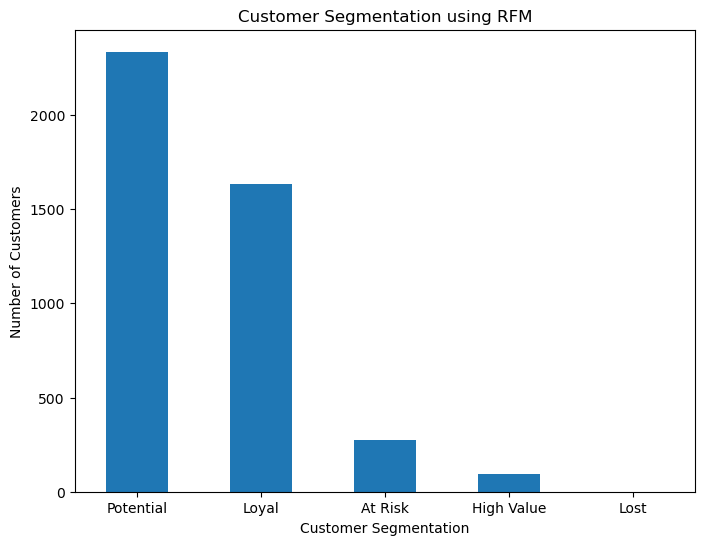

In [53]:
RFM["Segment"].value_counts().plot(kind="bar",figsize=(8,6))
plt.xlabel("Customer Segmentation")
plt.ylabel("Number of Customers")
plt.title("Customer Segmentation using RFM")
plt.xticks(rotation=0)


In [62]:
Segment_revenue=RFM.groupby("Segment")["Monetary"].sum()
Segment_revenue=Segment_revenue.sort_values(ascending=False)
Segment_revenue

Segment
Potential     7049387.431
Loyal         1309605.102
High Value     314108.521
At Risk        213906.720
Lost              201.120
Name: Monetary, dtype: float64

Text(0.5, 1.0, 'Revenue by Customer Segment')

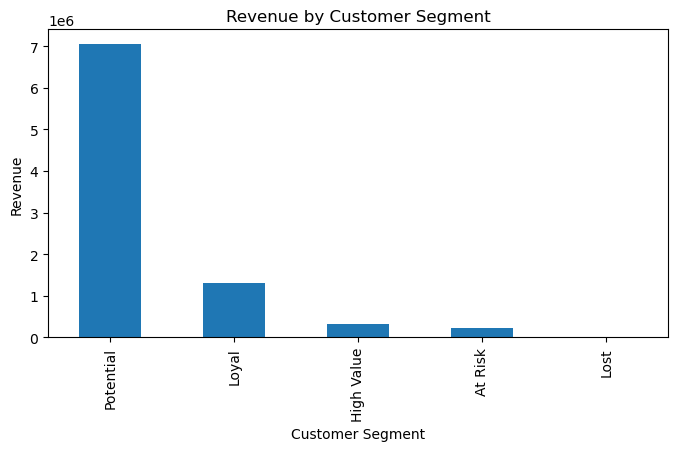

In [70]:
Segment_revenue.plot(kind="bar",figsize=(8,4))
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")
plt.title("Revenue by Customer Segment")


In [67]:
Segment_Count=RFM["Segment"].value_counts()
Segment_Count

Segment
Potential     2335
Loyal         1632
At Risk        275
High Value      96
Lost             1
Name: count, dtype: int64

In [75]:
lost_customer=RFM.groupby("Segment").get_group("Lost")
lost_customer

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Scores,Segment
CustomerID,,,,,,,,
17988.0,12,7,201.12,1,1,1,3,Lost


In [81]:
customer_orders=sales_df.groupby("CustomerID")["InvoiceNo"].nunique()
RFM["Orders"]=customer_orders
RFM["Orders"]

CustomerID
12346.0     1
12347.0     7
12348.0     4
12349.0     1
12350.0     1
           ..
18280.0     1
18281.0     1
18282.0     2
18283.0    16
18287.0     3
Name: Orders, Length: 4339, dtype: int64

In [84]:
#calculate Average order value
RFM["AOV"]=RFM["Monetary"]/RFM["Orders"]
RFM["AOV"]

CustomerID
12346.0    77183.600000
12347.0      615.714286
12348.0      449.310000
12349.0     1757.550000
12350.0      334.400000
               ...     
18280.0      180.600000
18281.0       80.820000
18282.0       89.025000
18283.0      127.845625
18287.0      612.426667
Name: AOV, Length: 4339, dtype: float64

<Axes: xlabel='Segment'>

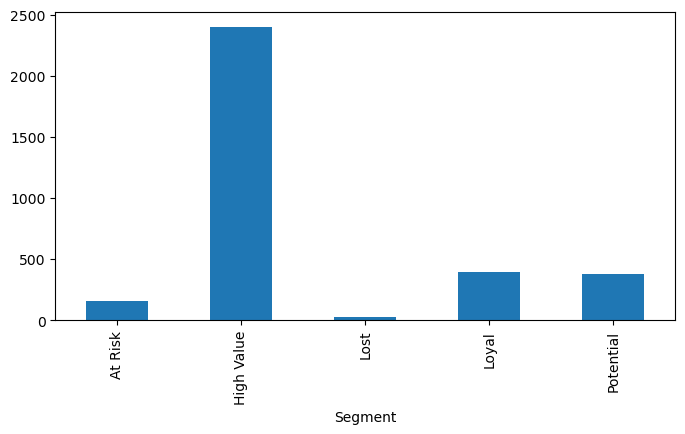

In [87]:
#segment AOV
Segment_AOV=RFM.groupby("Segment")["AOV"].mean()
Segment_AOV.plot(kind="bar",figsize=(8,4))

In [93]:
Correlation=df[["Quantity","UnitPrice","Revenue"]].corr()
Correlation

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.001243,0.916130
UnitPrice,-0.001243,1.000000,-0.129311
Revenue,0.916130,-0.129311,1.000000


Text(0.5, 1.0, 'Correlation between sales variables')

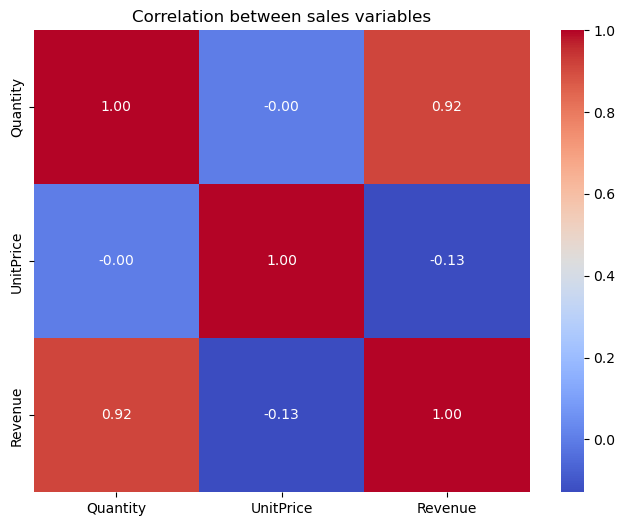

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
sns.heatmap(
            Correlation,
            annot=True,
            cmap="coolwarm",
            fmt=".2f"
           )
plt.title("Correlation between sales variables")

In [108]:
Total_revenue=sales_df["Revenue"].sum()
Total_Orders=sales_df["InvoiceNo"].nunique()
Total_Customers=sales_df["CustomerID"].nunique()
Total_Products=sales_df["Description"].nunique()

print("TOTAL_OREDRS",Total_Orders)
print("TOTAL_REVENUE",Total_revenue)
print("TOTAL_CUSTOMERS",Total_Customers)
print("TOTAL_PRODUCTS",Total_Products)

TOTAL_OREDRS 18536
TOTAL_REVENUE 8887208.894
TOTAL_CUSTOMERS 4339
TOTAL_PRODUCTS 3877


In [111]:
kpi={"TOTAL_REVENUE":Total_revenue,
     "TOTAL_REVENUE":Total_revenue,
     "TOTAL_CUSTOMERS":Total_Customers,
     "TOTAL_PRODUCTS":Total_Products,
     "RETURN_RATE":Return_rate}
kpi
     
     

{'TOTAL_REVENUE': np.float64(8887208.894),
 'TOTAL_CUSTOMERS': 4339,
 'TOTAL_PRODUCTS': 3877,
 'RETURN_RATE': np.float64(5.285346985976848)}

In [116]:
Final_Summary=pd.DataFrame({
    "metric":[
        "TOTAL_REVENUE",
        "TOTAL_ORDERS",
        "TOTAL_CUSTOMERS",
        "TOTAL_PRODUCTS",
        "RETURN_RATE",
        "AVERAGE_ORDER_VALUE"
    ],
    "value":[
        Total_revenue,
        Total_Orders,
        Total_Customers,
        Total_Products,
        Return_rate,
        AOV
    ]
})
Final_Summary


,metric,value
0,TOTAL_REVENUE,8.887209e+06
1,TOTAL_ORDERS,1.853600e+04
2,TOTAL_CUSTOMERS,4.339000e+03
3,TOTAL_PRODUCTS,3.877000e+03
4,RETURN_RATE,5.285347e+00
5,AVERAGE_ORDER_VALUE,4.794567e+02


In [127]:
print("TOP_COUNTRY:")
print(Country_revenue.idxmax())

print("\n TOP_PRODUCT_BY_REVENUE:")
print(Product_revenue.idxmax())

print("\n TOP_CUSTOMER_BY_REVENUE")
print(Customer_revenue.idxmax())

print("\n HIGHEST_REVENUE_BY_MONTH")
print(Monthly_Revenue.idxmax())

TOP_COUNTRY:
United Kingdom

 TOP_PRODUCT_BY_REVENUE:
REGENCY CAKESTAND 3 TIER

 TOP_CUSTOMER_BY_REVENUE
14646.0

 HIGHEST_REVENUE_BY_MONTH
2011-11
